# 02 · Dirección del *kick* y del espín: ¿puede una llamarada salir de este agujero negro?

**Contexto.** Al fusionarse, dos agujeros negros forman uno nuevo (el *remanente*) que puede salir despedido (*kick*) y que gira sobre sí mismo (*espín*). Una de las ideas para explicar una llamarada de luz tras una fusión es el mecanismo de **Blandford-Znajek**: el agujero negro final, rodeado de gas magnetizado, lanza un chorro (*jet*) de luz a lo largo de su eje de giro. Para que ese chorro apunte hacia nosotros (los observadores) hacen falta dos condiciones geométricas:

* $\theta_{aN} < 10^\circ$: el eje de giro del remanente forma menos de 10° con la **línea de visión** $N$.
* $\theta_{kN} < 90^\circ$: el *kick* tiene una componente **hacia** el observador (el remanente se acerca, no se aleja).

**Pregunta.** ¿Los datos de la señal gravitacional favorecen o desfavorecen esas dos condiciones, comparados con lo esperado antes de medir?

**Cómo se responde.** Igual que en el cuaderno 01 se usa el ratio de Savage-Dickey, ahora en su versión para **hipótesis de rango** («el ángulo es menor que…» en lugar de «el parámetro vale exactamente…»):

$$B = \frac{P_{\text{posterior}}(\theta<\theta_0)}{P_{\text{prior}}(\theta<\theta_0)}$$

Es decir, la fracción de muestras del posterior que cumplen la condición dividida por la fracción de muestras del prior que la cumplen. Los posteriores usados aquí ya están **condicionados a la posición en el cielo y la distancia de la llamarada**, por lo que el factor resultante es condicional a ellas (ver el apartado final).

*Datos: muestras del remanente (kick y espín) calculadas por el tutor a partir de las muestras de GW190521 con el modelo surrogate `surfinBH`; ver `data/README.md`.*

In [1]:
import sys
sys.path.insert(0, "../src")

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.patches as patches
import corner

import tfg_bayes as tb

tb.set_paper_style(font_size=12)
%matplotlib inline

## 1. Ángulos de prior y posterior

El archivo de posterior ya trae $\theta_{aN}$ y $\theta_{kN}$. En el prior hay que calcular $\theta_{aN}$ a partir de vectores:

* línea de visión: $N = (\sin\iota\cos\phi,\ \sin\iota\sin\phi,\ \cos\iota)$, con $\iota$ la inclinación y $\phi$ la fase;
* espín final $S$ (vector de 3 componentes);
* $\cos\theta_{aN} = \dfrac{S\cdot N}{|S|}$ (porque $|N|=1$).

In [2]:
post, prior = tb.load_kick_spin()

# --- Posterior (radianes -> grados) ---
theta_an_post = np.degrees(post["theta_an"])
theta_kn_post = np.degrees(post["theta_kn"])

# --- Prior: theta_an a partir de la línea de visión N y del espín S ---
Nx = np.sin(prior["iota"]) * np.cos(prior["phase"])
Ny = np.sin(prior["iota"]) * np.sin(prior["phase"])
Nz = np.cos(prior["iota"])
Sx, Sy, Sz = prior["spin_x"], prior["spin_y"], prior["spin_z"]
Smag = np.sqrt(Sx**2 + Sy**2 + Sz**2)
cos_theta_an = np.clip((Sx * Nx + Sy * Ny + Sz * Nz) / Smag, -1.0, 1.0)
theta_an_prior = np.degrees(np.arccos(cos_theta_an))
theta_kn_prior = np.degrees(prior["theta_kn"])

print(f"Muestras: posterior {len(theta_an_post):,}   prior {len(theta_an_prior):,}")

Muestras: posterior 50,000   prior 50,000


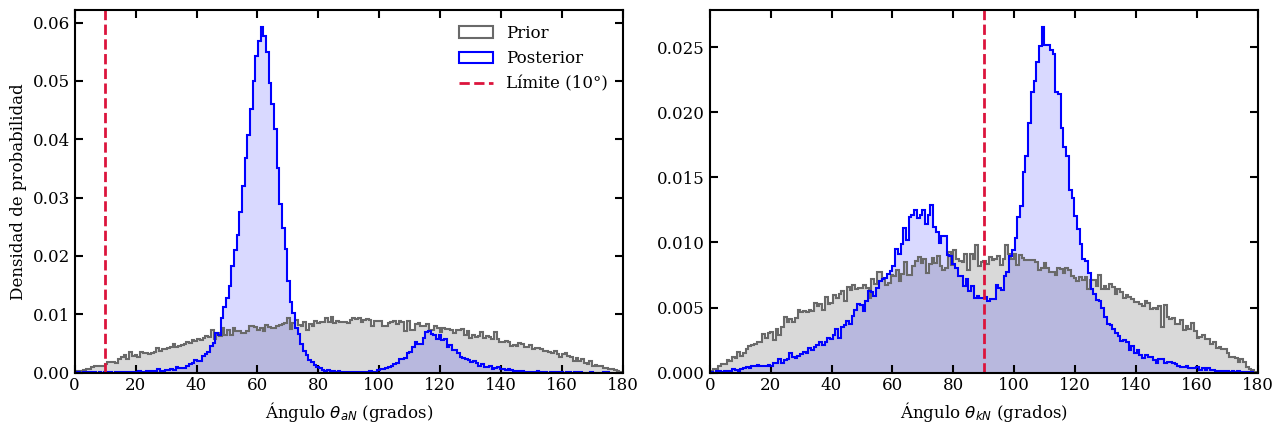

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, prior_x, post_x, lim, xlabel in [
    (axes[0], theta_an_prior, theta_an_post, 10, r"Ángulo $\theta_{aN}$ (grados)"),
    (axes[1], theta_kn_prior, theta_kn_post, 90, r"Ángulo $\theta_{kN}$ (grados)"),
]:
    ax.hist(prior_x, bins=200, density=True, histtype="stepfilled", color="dimgray", alpha=0.25)
    ax.hist(prior_x, bins=200, density=True, histtype="step", color="dimgray", lw=1.5, label="Prior")
    ax.hist(post_x, bins=200, density=True, histtype="stepfilled", color="blue", alpha=0.15)
    ax.hist(post_x, bins=200, density=True, histtype="step", color="blue", lw=1.5, label="Posterior")
    ax.axvline(lim, color="crimson", ls="--", lw=2, label=f"Límite ({lim}°)")
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, 180)
axes[0].set_ylabel("Densidad de probabilidad")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. Factor de Bayes de cada ángulo por separado

La función `frac_cumulative(x, x0, L)` cuenta la fracción de muestras con $|x-x_0|<L$. Con $x_0=0$ y ángulos positivos equivale a «$x<L$», que es justo la hipótesis de rango.

Primero se barre el umbral $L$ (para ver cómo cambia el cociente) y se marca el umbral físico; los intervalos son bootstrap con 100 réplicas.

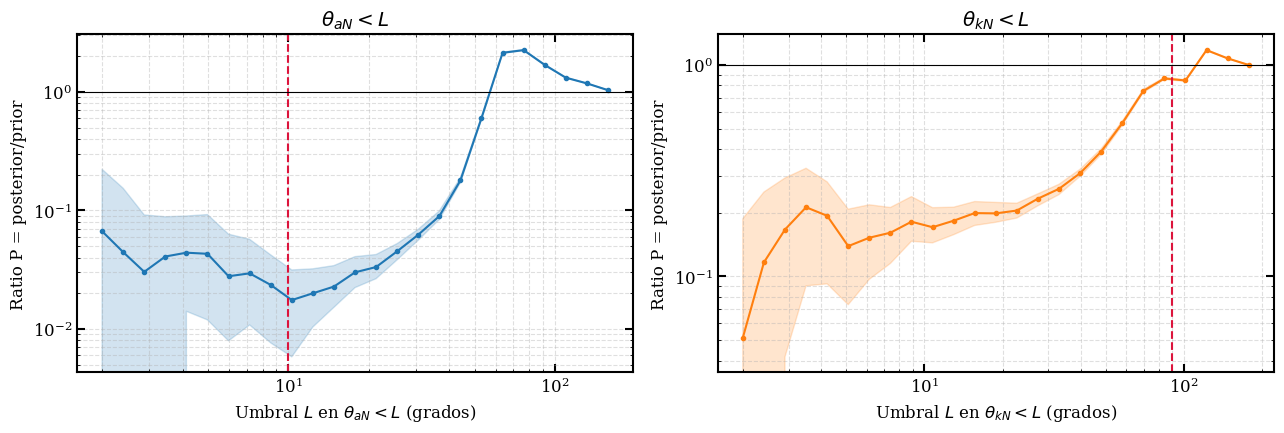

In [4]:
cum = lambda cols, L: tb.frac_cumulative(cols[0], 0.0, L)

L_an = np.logspace(0.3, 2.2, 25)      # grados
L_kn = np.logspace(0.3, 2.25, 25)     # grados

P_an = tb.bootstrap_ratio((theta_an_post,), (theta_an_prior,), cum, L_an, seed=41)
P_kn = tb.bootstrap_ratio((theta_kn_post,), (theta_kn_prior,), cum, L_kn, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
tb.plot_bootstrap(L_an, P_an, r"Umbral $L$ en $\theta_{aN}<L$ (grados)", ax=axes[0], color="C0")
axes[0].axvline(10, color="crimson", ls="--"); axes[0].set_title(r"$\theta_{aN} < L$")
tb.plot_bootstrap(L_kn, P_kn, r"Umbral $L$ en $\theta_{kN}<L$ (grados)", ax=axes[1], color="C1")
axes[1].axvline(90, color="crimson", ls="--"); axes[1].set_title(r"$\theta_{kN} < L$")
for ax in axes:
    ax.axhline(1, color="k", lw=0.8)
plt.tight_layout()
plt.show()

In [5]:
def resultado(nombre, post_cols, prior_cols, fraction, L0, seed):
    # Valor puntual y bootstrap en el umbral físico L0
    f_post, f_prior = fraction(post_cols, L0), fraction(prior_cols, L0)
    P = tb.bootstrap_ratio(post_cols, prior_cols, fraction, [L0], n_boot=1000, seed=seed)[:, 0]
    lo, med, hi = np.nanpercentile(P, [5, 50, 95])
    print(f"{nombre:<34} f_post={f_post:.2e} ({f_post*len(post_cols[0]):.0f} muestras)  "
          f"f_prior={f_prior:.2e}  B={f_post/f_prior:.3f}   bootstrap: {med:.3f} [{lo:.3f}, {hi:.3f}]")
    return f_post / f_prior

B_an = resultado(r"theta_aN < 10°", (theta_an_post,), (theta_an_prior,), cum, 10.0, 51)
B_kn = resultado(r"theta_kN < 90°", (theta_kn_post,), (theta_kn_prior,), cum, 90.0, 52)

theta_aN < 10°                     f_post=1.40e-04 (7 muestras)  f_prior=7.22e-03  B=0.019   bootstrap: 0.018 [0.008, 0.032]


theta_kN < 90°                     f_post=4.23e-01 (21157 muestras)  f_prior=4.99e-01  B=0.847   bootstrap: 0.848 [0.838, 0.857]


## 3. Factor de Bayes conjunto ($\theta_{aN}<10^\circ$ **y** $\theta_{kN}<90^\circ$)

Los dos ángulos no son independientes, así que el factor conjunto no es el producto de los individuales: se cuentan las muestras que cumplen **ambas** condiciones a la vez. En el bootstrap, cada muestra conserva sus dos ángulos (mismos índices).

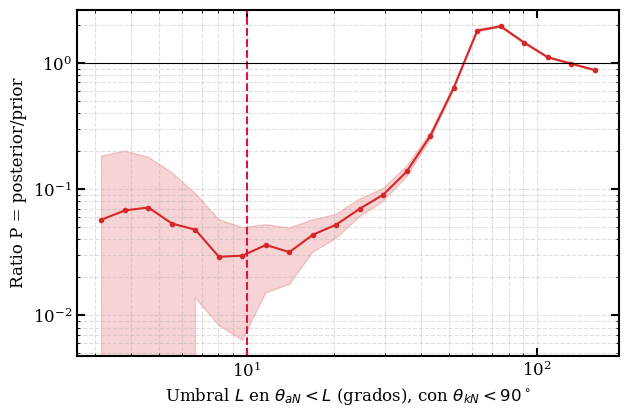

theta_aN<10° y theta_kN<90°        f_post=1.00e-04 (5 muestras)  f_prior=3.62e-03  B=0.028   bootstrap: 0.027 [0.011, 0.050]


In [6]:
cum2d = lambda cols, L: tb.frac_cumulative_2d(cols[0], cols[1], L, 90.0)

# Barrido del umbral de theta_aN con theta_kN < 90° fijo
L_an2 = np.logspace(0.5, 2.2, 22)
P_2d = tb.bootstrap_ratio((theta_an_post, theta_kn_post), (theta_an_prior, theta_kn_prior), cum2d, L_an2, seed=61)

fig, ax = plt.subplots(figsize=(7, 4.5))
tb.plot_bootstrap(L_an2, P_2d, r"Umbral $L$ en $\theta_{aN}<L$ (grados), con $\theta_{kN}<90^\circ$", ax=ax, color="C3")
ax.axvline(10, color="crimson", ls="--"); ax.axhline(1, color="k", lw=0.8)
plt.show()

B_joint = resultado(r"theta_aN<10° y theta_kN<90°", (theta_an_post, theta_kn_post),
                    (theta_an_prior, theta_kn_prior), cum2d, 10.0, 53)

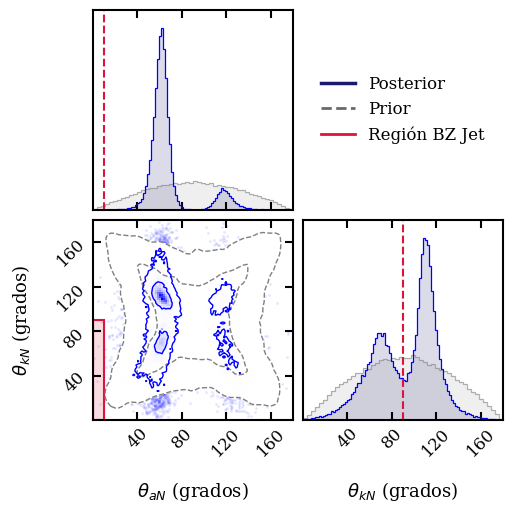

In [7]:
# Región de interés sobre las nubes de puntos de prior (gris) y posterior (azul)
data_post = np.vstack([theta_an_post, theta_kn_post]).T
data_prior = np.vstack([theta_an_prior, theta_kn_prior]).T
range_limits = [(0, 180), (0, 180)]
lim_an, lim_kn = 10, 90
labels = [r"$\theta_{aN}$ (grados)", r"$\theta_{kN}$ (grados)"]

fig = corner.corner(data_prior, bins=50, smooth=True, range=range_limits, color="gray",
                    plot_datapoints=False, plot_density=False, levels=[0.5, 0.9],
                    hist_kwargs={"density": True, "linewidth": 0.9, "histtype": "step", "alpha": 0.6},
                    contour_kwargs={"linewidths": 1, "linestyles": "dashed"},
                    labels=labels, label_kwargs={"fontsize": 13})
corner.corner(data_prior, range=range_limits, bins=50, smooth=True, color="silver", fig=fig,
              plot_datapoints=False, plot_density=False, plot_contours=False,
              hist_kwargs={"density": True, "histtype": "stepfilled", "alpha": 0.25})
corner.corner(data_post, bins=100, range=range_limits, color="blue", fig=fig,
              plot_datapoints=True, levels=[0.393, 0.865],
              hist_kwargs={"density": True, "linewidth": 0.9, "histtype": "step"},
              contour_kwargs={"linewidths": 1})
corner.corner(data_post, bins=100, range=range_limits, color="midnightblue", fig=fig,
              plot_datapoints=False, plot_density=False, plot_contours=False,
              hist_kwargs={"density": True, "histtype": "stepfilled", "alpha": 0.15})

axes = np.array(fig.axes).reshape(2, 2)
axes[1, 0].add_patch(patches.Rectangle((0, 0), lim_an, lim_kn, lw=1, ec="crimson", fc="crimson", alpha=0.15))
axes[1, 0].add_patch(patches.Rectangle((0, 0), lim_an, lim_kn, lw=1.5, ec="crimson", fc="none"))
axes[0, 0].axvline(lim_an, color="crimson", ls="--", lw=1.5)
axes[1, 1].axvline(lim_kn, color="crimson", ls="--", lw=1.5)
axes[0, 1].axis("off")
axes[0, 1].legend(handles=[mlines.Line2D([], [], color="midnightblue", lw=2.5, label="Posterior"),
                           mlines.Line2D([], [], color="dimgray", ls="--", lw=2, label="Prior"),
                           mlines.Line2D([], [], color="crimson", lw=2, label="Región BZ Jet")],
                  loc="center", fontsize=12, frameon=False)
plt.show()

## 4. Combinación con el cielo y la distancia

Como los posteriors angulares ya están condicionados al cielo y a la distancia de la llamarada, el factor de Bayes total se obtiene multiplicando (regla del producto):

$$B_C = B_{\Omega,d_L}\cdot B_{\theta_{kN},\theta_{aN}\mid\Omega,d_L}$$

y las probabilidades relativas (*odds*) se obtienen con la probabilidad a priori de la hipótesis de fuente común, $\pi_C\approx 1/13$ (la inversa del número de llamaradas parecidas a ZTF19abanrhr, según la memoria):

$$O_C = B_C\cdot\pi_C .$$

$B_{\Omega,d_L}$ es el factor del cuaderno 01. Se muestran dos escenarios: el valor que figura en la memoria y el recalculado en el cuaderno 01 con el prior exacto.

In [8]:
pi_C = 1 / 13

try:
    with open("../results/b_sky_distance.json", encoding="utf-8") as f:
        recalc = json.load(f)
    B_sky_recalc = recalc["B_sky_dl_L0.2rad_200Mpc"]
except FileNotFoundError:
    B_sky_recalc = None     # ejecutar antes el cuaderno 01

escenarios = {"Memoria (B_Ω,dl = 30; B_θ = 0,03)": (30.0, 0.03)}
if B_sky_recalc is not None:
    escenarios[f"Recalculado (B_Ω,dl = {B_sky_recalc:.0f}; B_θ = {B_joint:.3f})"] = (B_sky_recalc, B_joint)

print(f"{'Escenario':<46} {'B_C':>6} {'O_C':>7}   interpretación")
for nombre, (B_sky, B_ang) in escenarios.items():
    B_C = B_sky * B_ang
    O_C = B_C * pi_C
    print(f"{nombre:<46} {B_C:6.2f} {O_C:7.3f}   la coincidencia aleatoria es ~{1/O_C:.0f} veces más probable")

Escenario                                         B_C     O_C   interpretación
Memoria (B_Ω,dl = 30; B_θ = 0,03)                0.90   0.069   la coincidencia aleatoria es ~14 veces más probable
Recalculado (B_Ω,dl = 90; B_θ = 0.028)           2.47   0.190   la coincidencia aleatoria es ~5 veces más probable


## 5. Resumen

| Hipótesis | Recalculado aquí | Memoria |
|---|---|---|
| $\theta_{kN}<90^\circ$ | $B\approx0{,}85$ | $\approx1$ |
| $\theta_{aN}<10^\circ$ | $B\approx0{,}02$ | $\approx0{,}03$ |
| ambas a la vez | $B\approx0{,}03$ | $\approx0{,}03$ |

* **$\theta_{kN}<90^\circ$ es indiferente** ($B\sim1$): los datos no favorecen ni desfavorecen que el remanente se acerque al observador.
* **$\theta_{aN}<10^\circ$ está muy desfavorecida** ($B\sim0{,}02$–$0{,}03$, unas 30–50 veces menos probable que antes de medir): el posterior casi no tiene muestras con el eje de giro tan alineado con la línea de visión. El factor conjunto está dominado por este ángulo.
* **Cautela estadística.** Esa conclusión descansa en muy pocas muestras del posterior: solo unas 7 de 50 000 cumplen $\theta_{aN}<10^\circ$ y 5 cumplen ambas condiciones, por lo que el factor conjunto tiene una incertidumbre relativa grande (el intervalo del 90 % del bootstrap se ve en la tabla de arriba). Que sea mucho menor que 1 es robusto; su valor exacto, no.
* En el apartado 4, con cualquiera de los dos valores del factor 3D del cielo, las *odds* quedan por debajo de 1, de modo que la hipótesis de fuente común mediante Blandford-Znajek sale desfavorecida; con el valor recalculado en el cuaderno 01 la diferencia respecto a la coincidencia aleatoria es menor (≈ 5 veces) que con el de la memoria (≈ 15 veces).